In [37]:
import pandas as pd
import seaborn as sns
import aquarel

In [38]:
(
    pd.read_parquet("../data/processed/robust04-eval_scores.parquet")
    .reset_index()
    .loc[:, ["system", "query", "depth", "ndcg_original"]]
    .drop_duplicates()
)

,system,query,depth,ndcg_original
0,humR04t1,301,5,0.485229
1,humR04t1,304,5,0.131205
2,humR04t1,306,5,1.000000
3,humR04t1,307,5,0.722727
4,humR04t1,311,5,1.000000
...,...,...,...,...
21115,uogRobDWR10,631,1000,0.640574
21116,uogRobDWR10,656,1000,0.890678
21117,uogRobDWR10,683,1000,0.742100
21118,uogRobDWR10,688,1000,0.606432


In [71]:
import seaborn as sns

tmp = (
    pd.concat([
        pd.concat([
            pd.read_parquet(f"../data/processed/robust04-eval-subsampled-default_fillna_{i}.parquet")
            for i in [0,1,2,3,4,5,6,7,10,11,12,13,14]
        ]),
        pd.concat([
            pd.read_parquet(f"../data/processed/robust04-eval-subsampled-predicted_fillna_{i}.parquet")
            for i in [0,1,2,3,4,5,6,7,10,11,12,13,14]
        ]),
    ])
    .drop(columns=["in_pool", "index", "unjudged_ratio"])
    .assign(
        depth=lambda df: df["metric"].apply(lambda row: int(row.split("@")[-1])),
        metric=lambda df: df["metric"].apply(lambda row: row.split("@")[0])
    )
    .pivot(index=["source", "iteration", "run_sample_rate", "system", "query", "depth"], columns="metric", values="value")
    .reset_index()
    .merge(
        (
            pd.read_parquet("../data/processed/robust04-eval_scores.parquet")
            .reset_index()
            .loc[:, ["system", "query", "depth", "ndcg_original"]]
            .drop_duplicates()
        ),
        on=["query", "system", "depth"],
        how="left"
    )
    .drop(columns="query")
    .groupby(["system", "depth", "run_sample_rate", "iteration", "source"])
    .mean()
    .reset_index()
)

corr = (
    tmp
    .drop(columns=["system", "UNJ"])
    .groupby(["run_sample_rate", "iteration", "depth", "source"])
    .corr(method="spearman")
    .reset_index()
    .query("level_4 == 'ndcg_original'")
    .drop(columns=["level_4", "ndcg_original"])
)


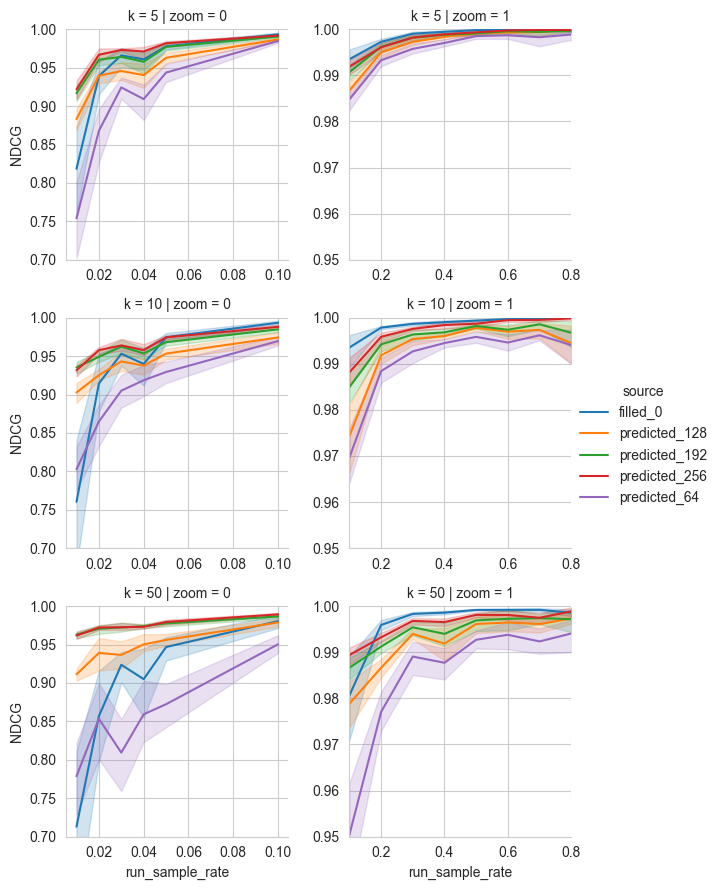

In [72]:
g = sns.FacetGrid(
    data=pd.concat([
        (
            corr
            .query("depth in [5,10,50]")
            .query("source != 'filled_1'")
            .query("run_sample_rate >= 0.1")
            .rename(columns={"depth": "k"})
            .assign(zoom=1)
        ),
        (
            corr
            .query("depth in [5,10,50]")
            .query("source != 'filled_1'")
            .query("run_sample_rate <= 0.1")
            .rename(columns={"depth": "k"})
            .assign(zoom=0)
        )
    ]),
    row="k",
    col="zoom",
    hue="source",
    sharey=False,
    sharex=False,
    legend_out=True,
)
g.map(
    sns.lineplot,
    "run_sample_rate",
    "NDCG",
)

for ax in g.axes[:, 0]:
    ax.set_ylim(0.7, 1)
for ax in g.axes[:, 1]:
    ax.set_ylim(0.95, 1)
    ax.set_xlim(0.1, .8)

g.add_legend()
g.savefig("figure-correlation-subsampling.pdf")

In [41]:
tmp.columns

Index(['system', 'depth', 'run_sample_rate', 'iteration', 'source', 'NDCG',
       'UNJ', 'ndcg_original'],
      dtype='object')

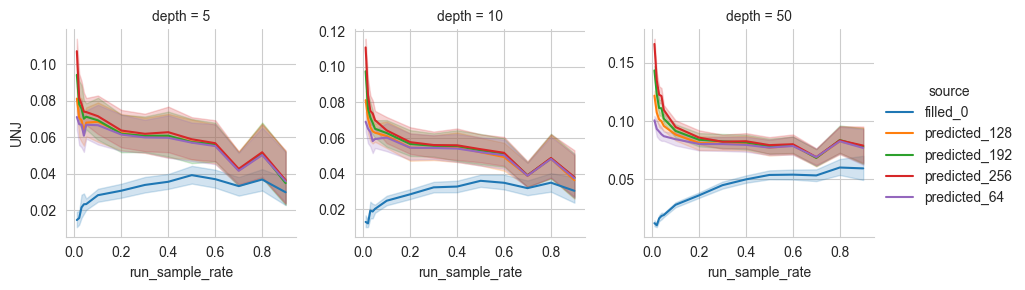

In [73]:
g = sns.FacetGrid(
    data=(
        (
            tmp
            .loc[:, ["depth", "run_sample_rate", "iteration", "source", "UNJ"]]
            .drop_duplicates()
        )
        .query("depth in [5,10,50]")
        .query("source != 'filled_1'")
    ),
    col="depth",
    hue="source",
    sharey=False,
    legend_out=True,
)
g.map(
    sns.lineplot,
    "run_sample_rate",
    "UNJ",
)
g.add_legend()

In [43]:
(
    (
        tmp
        .loc[:, ["depth", "run_sample_rate", "iteration", "source", "UNJ"]]
        .drop_duplicates()
    )
    .query("depth in [5,10,50]")
    .query("source != 'filled_1'")
    .groupby(["depth", "run_sample_rate", "iteration", "source"])
    .describe()
)

UNJ                      \
                                              count      mean       std   
depth run_sample_rate iteration source                                    
5     0.01            0         filled_0        5.0  0.009167  0.008015   
                                predicted_128  35.0  0.082381  0.075367   
                                predicted_192  35.0  0.092619  0.079874   
                                predicted_256  43.0  0.107946  0.075647   
                                predicted_64   32.0  0.068750  0.075780   
...                                             ...       ...       ...   
50    0.90            0         filled_0       10.0  0.054583  0.041917   
                                predicted_128  11.0  0.056023  0.030134   
                                predicted_192  11.0  0.056212  0.030272   
                                predicted_256  11.0  0.056288  0.030354   
                                predicted_64   11.0  0.055985  0.030192   

                                                                             \
                                                    min       25%       50%   
depth run_sample_rate iteration source                                        
5     0.01            0         filled_0       0.000000  0.004167  0.008333   
                                predicted_128  0.004167  0.039583  0.066667   
                                predicted_192  0.004167  0.047917  0.075000   
                                predicted_256  0.008333  0.060417  0.095833   
                                predicted_64   0.000000  0.028125  0.052083   
...                                                 ...       ...       ...   
50    0.90            0         filled_0       0.012083  0.030625  0.044167   
                                predicted_128  0.014167  0.032500  0.047500   
                                predicted_192  0.014167  0.032708  0.047500   
                                predicted_256  0.014167  0.032708  0.047500   
                                predicted_64   0.013750  0.032500  0.047500   

                                                                   
                                                    75%       max  
depth run_sample_rate iteration source                             
5     0.01            0         filled_0       0.012500  0.020833  
                                predicted_128  0.104167  0.437500  
                                predicted_192  0.116667  0.458333  
                                predicted_256  0.137500  0.466667  
                                predicted_64   0.085417  0.425000  
...                                                 ...       ...  
50    0.90            0         filled_0       0.065833  0.160833  
                                predicted_128  0.085417  0.098333  
                                predicted_192  0.086042  0.098333  
                                predicted_256  0.086458  0.098333  
                                predicted_64   0.085417  0.098333  

[165 rows x 8 columns]